In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os
import pathlib

image_path = pathlib.Path(os.path.join(os.getcwd(), "Images"))
print(image_path)

d:\GIT\Teaching Material\2025-26\3rd Sem\DIP Lab - AIML\Source Code\Expt 5\Images


In [2]:
try:
    img = cv2.imread(image_path / 'building.tif', cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError("Image not found. Check the path.")
    print("Image read successfully!")
except Exception as e:
    print(f"Error loading image: {e}")

Image read successfully!


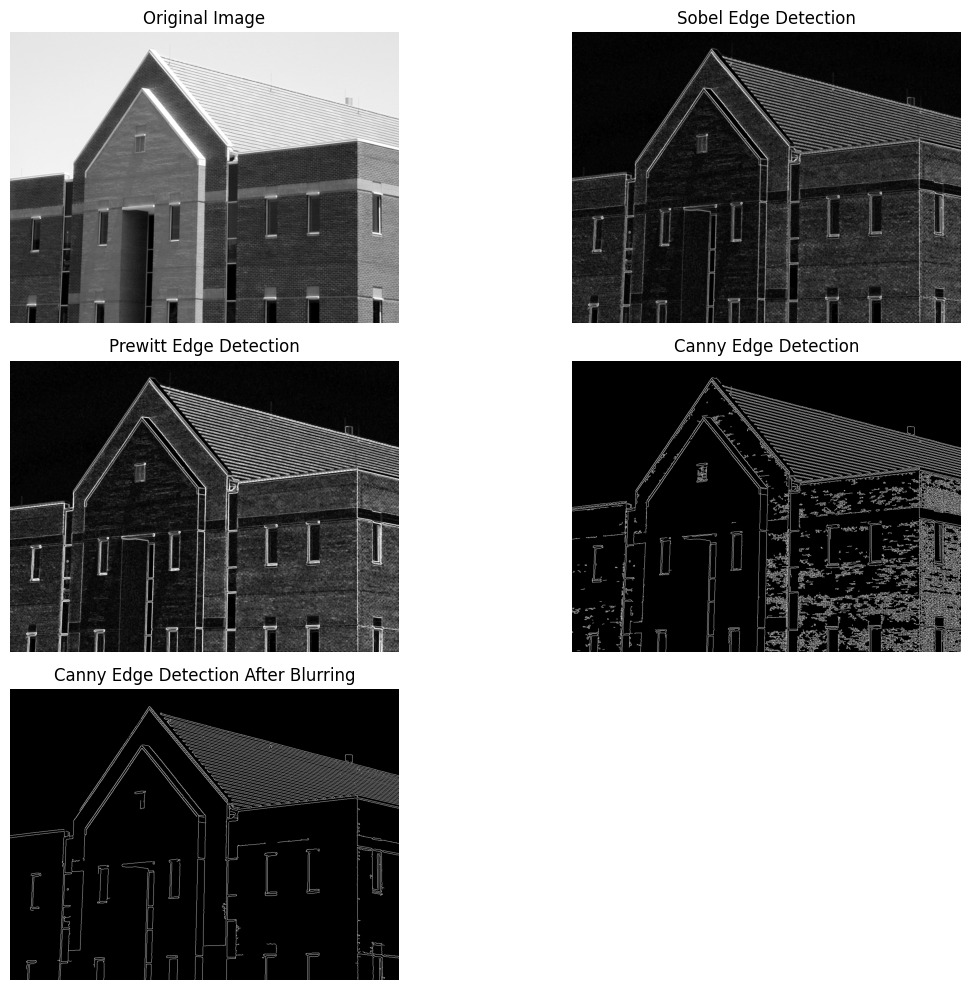

In [5]:
# --- 1. Sobel Edge Detection ---
# ksize=3 indicates a 3x3 kernel.
# CV_64F is used to handle negative derivatives (slopes) which standard uint8 cannot hold.
grad_x_sobel = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
grad_y_sobel = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)

# Calculate Magnitude: sqrt(Gx^2 + Gy^2)
abs_grad_x_sobel = cv2.convertScaleAbs(grad_x_sobel)
abs_grad_y_sobel = cv2.convertScaleAbs(grad_y_sobel)
sobel_combined = cv2.addWeighted(abs_grad_x_sobel, 0.5, abs_grad_y_sobel, 0.5, 0)

# --- 2. Prewitt Edge Detection ---
# OpenCV does not have a specific Prewitt function, so we define the kernels manually.
prewitt_kernel_x = np.array([[ -1, 0, 1],
                             [ -1, 0, 1],
                             [ -1, 0, 1]])

prewitt_kernel_y = np.array([[ -1, -1, -1],
                             [  0,  0,  0],
                             [  1,  1,  1]])

grad_x_prewitt = cv2.filter2D(img, -1, prewitt_kernel_x)
grad_y_prewitt = cv2.filter2D(img, -1, prewitt_kernel_y)

# Combine Prewitt X and Y (Using absolute summation approximation)
# Note: Since we used filter2D with default depth, negatives might be clamped to 0 unless we use float
# For better accuracy, convert to float first, then filter, then abs:
img_float = img.astype(np.float32)
grad_x_prewitt_f = cv2.filter2D(img_float, -1, prewitt_kernel_x)
grad_y_prewitt_f = cv2.filter2D(img_float, -1, prewitt_kernel_y)
prewitt_combined = cv2.convertScaleAbs(np.sqrt(grad_x_prewitt_f**2 + grad_y_prewitt_f**2))

# --- 3. Canny Edge Detection ---
# Threshold1: Min val, Threshold2: Max val (for hysteresis)
canny_edges = cv2.Canny(img, 100, 200)
blurred_img = cv2.GaussianBlur(img, (5, 5), 1.5)
canny_edges_clean = cv2.Canny(blurred_img, 50, 150)

# --- Display Results ---
plt.figure(figsize=(12, 10))

titles = ['Original Image', 'Sobel Edge Detection', 'Prewitt Edge Detection', 'Canny Edge Detection', 'Canny Edge Detection After Blurring']
images = [img, sobel_combined, prewitt_combined, canny_edges, canny_edges_clean]

for i in range(5):
    plt.subplot(3, 2, i+1)
    plt.imshow(images[i], cmap='gray')
    plt.title(titles[i])
    plt.axis('off')

plt.tight_layout()
plt.show()